# Artificial Neural Network (ANN) dan Evaluasi Classifier

# Praktikum 1

Langkah:

1. Buat dataset sederhana (XOR).
2. Inisialisasi bobot dan bias.
3. Implementasikan forward pass.
4. Hitung error dan lakukan backpropagation.
5. Update bobot menggunakan gradient descent.

In [1]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.2839085928591663
Epoch 1000, Loss: 0.24815774300164817
Epoch 2000, Loss: 0.22543617738441746
Epoch 3000, Loss: 0.11793810105920516
Epoch 4000, Loss: 0.024966188365445736
Epoch 5000, Loss: 0.010813227363213527
Epoch 6000, Loss: 0.006548816104483789
Epoch 7000, Loss: 0.004607795247764838
Epoch 8000, Loss: 0.0035215802913183686
Epoch 9000, Loss: 0.002834839051155324
Prediksi:
[[0.04922209]
 [0.95513252]
 [0.94372282]
 [0.04308284]]


Tugas 1:

1. Ubah jumlah neuron hidden layer menjadi 3.
2. Bandingkan hasil loss dengan konfigurasi awal.
3. Tambahkan fungsi aktivasi ReLU dan bandingkan hasil.

1. Ubah jumlah neuron hidden layer menjadi 3.

In [2]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 3   # <-- diubah jadi 3
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training
print("=== Training dengan Hidden Neuron = 3 (Sigmoid) ===")
for epoch in range(10000):
    # Forward
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Error
    error = y - a2

    # Backprop
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

print("\nPrediksi akhir:")
print(a2)


=== Training dengan Hidden Neuron = 3 (Sigmoid) ===
Epoch 0, Loss: 0.2561747433655268
Epoch 1000, Loss: 0.238576193320799
Epoch 2000, Loss: 0.2055225371017337
Epoch 3000, Loss: 0.16927704953345982
Epoch 4000, Loss: 0.14855215288334409
Epoch 5000, Loss: 0.13915094771497652
Epoch 6000, Loss: 0.12024179194371051
Epoch 7000, Loss: 0.022317794614491793
Epoch 8000, Loss: 0.009928515572043599
Epoch 9000, Loss: 0.0060850811356940844

Prediksi akhir:
[[0.06381261]
 [0.93840967]
 [0.93553733]
 [0.07224157]]


2. Bandingkan hasil loss dengan konfigurasi awal.

In [3]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# -------------------------------------------
# Fungsi untuk training dan mengembalikan loss
# -------------------------------------------
def train_model(hidden_size, lr=0.1, epoch_total=10000):
    input_size = 2
    output_size = 1

    # Inisialisasi bobot
    W1 = np.random.randn(input_size, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size)
    b2 = np.zeros((1, output_size))

    for epoch in range(epoch_total):

        # Forward
        z1 = np.dot(X, W1) + b1
        a1 = sigmoid(z1)
        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)

        # Error
        error = y - a2

        # Backprop
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    # Hitung loss akhir
    final_loss = np.mean(np.square(error))
    return final_loss

# -------------------------------------------
# Bandingkan konfigurasi awal vs baru
# -------------------------------------------
loss_hidden2 = train_model(hidden_size=2)
loss_hidden3 = train_model(hidden_size=3)

print("=== Perbandingan Loss ===")
print(f"Loss (hidden=2 neuron): {loss_hidden2}")
print(f"Loss (hidden=3 neuron): {loss_hidden3}")

if loss_hidden3 < loss_hidden2:
    print("Hidden layer 3 neuron memberikan hasil yang lebih baik!")
else:
    print("Hidden layer 2 neuron lebih stabil dalam percobaan ini.")


=== Perbandingan Loss ===
Loss (hidden=2 neuron): 0.1280008377614681
Loss (hidden=3 neuron): 0.0025349280655213666
Hidden layer 3 neuron memberikan hasil yang lebih baik!


3. Tambahkan fungsi aktivasi ReLU dan bandingkan hasil.

In [4]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# --- Aktivasi ---
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

# ---------------------------------------------------
# Fungsi training (bisa pilih 'sigmoid' atau 'relu')
# ---------------------------------------------------
def train_model(hidden_size, activation="sigmoid", lr=0.1, epoch_total=10000):

    input_size = 2
    output_size = 1

    # Inisialisasi bobot
    W1 = np.random.randn(input_size, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size)
    b2 = np.zeros((1, output_size))

    for epoch in range(epoch_total):

        # Forward
        z1 = np.dot(X, W1) + b1

        # Aktivasi hidden layer
        if activation == "sigmoid":
            a1 = sigmoid(z1)
        elif activation == "relu":
            a1 = relu(z1)

        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)  # Output tetap sigmoid

        # Error
        error = y - a2

        # Backprop output layer
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        # Backprop hidden layer pakai aktivasi yang dipilih
        if activation == "sigmoid":
            d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
        elif activation == "relu":
            d_a1 = np.dot(d_a2, W2.T) * relu_derivative(z1)

        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    # Hitung loss akhir
    final_loss = np.mean(np.square(error))
    return final_loss

# ---------------------------------------------------
# Bandingkan Sigmoid vs ReLU
# ---------------------------------------------------
loss_sigmoid = train_model(hidden_size=3, activation="sigmoid")
loss_relu    = train_model(hidden_size=3, activation="relu")

print("=== Perbandingan Loss (Hidden = 3 neuron) ===")
print(f"Loss dengan Sigmoid: {loss_sigmoid}")
print(f"Loss dengan ReLU   : {loss_relu}")

if loss_relu < loss_sigmoid:
    print("ReLU lebih baik pada konfigurasi ini!")
else:
    print("Sigmoid lebih stabil dalam percobaan ini.")


=== Perbandingan Loss (Hidden = 3 neuron) ===
Loss dengan Sigmoid: 0.002368816289434588
Loss dengan ReLU   : 0.00024319862778203233
ReLU lebih baik pada konfigurasi ini!


# Praktikum 2

Langkah:

1. Import library.
2. Load dataset.
3. Bangun model.
4. Kompilasi dan latih model.
5. Evaluasi hasil.

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
model.fit(X_train, y_train, epochs=50, batch_size=8)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi: {acc}")

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3433 - loss: 2.6133
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2872 - loss: 2.1426 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2709 - loss: 1.5972 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3358 - loss: 1.2656 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3124 - loss: 1.1380 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4026 - loss: 1.0434 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6867 - loss: 1.0031 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6567 - loss: 1.0094 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6715 - loss: 0.9858 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6958 - loss: 0.9747 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6095 - loss: 0.9594 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5313 - los

# Tugas 2

Ubah jumlah neuron hidden layer.

In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding (perbaikan)
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# === Ubah jumlah neuron hidden layer (Nomor 1) ===
model = tf.keras.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(4,)),  # ubah neuron
    tf.keras.layers.Dense(12, activation='relu'),                    # ubah neuron
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi dan latih
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=50, batch_size=8)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi (setelah ubah neuron): {acc}")


Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3414 - loss: 1.2069   
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5194 - loss: 1.0439 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4120 - loss: 0.9982 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5871 - loss: 0.9520 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7010 - loss: 0.9152 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7412 - loss: 0.8539 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7463 - loss: 0.8248 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8775 - loss: 0.7996 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7579 - loss: 0.7630 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7461 - loss: 0.7114 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7779 - loss: 0.6886 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9076 - 

Bandingkan akurasi dengan konfigurasi awal.

In [12]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# =====================
# Model 1: Konfigurasi Awal (10, 8)
# =====================
model_awal = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_awal.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_awal.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

loss1, acc1 = model_awal.evaluate(X_test, y_test, verbose=0)

# =====================
# Model 2: Konfigurasi Baru (16, 12)
# =====================
model_baru = tf.keras.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(12, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_baru.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_baru.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

loss2, acc2 = model_baru.evaluate(X_test, y_test, verbose=0)

# =====================
# Perbandingan hasil
# =====================
print("=== Perbandingan Akurasi ===")
print(f"Akurasi Model Awal (10, 8)  : {acc1:.4f}")
print(f"Akurasi Model Baru (16, 12) : {acc2:.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


=== Perbandingan Akurasi ===
Akurasi Model Awal (10, 8)  : 1.0000
Akurasi Model Baru (16, 12) : 0.9667


# Tugas 3

1. Bandingkan Sigmoid vs ReLU pada dataset Iris.
2. Catat perbedaan loss dan akurasi.

In [13]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load data
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding (versi baru)
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# ================================
# Model 1: Aktivasi SIGMOID
# ================================
model_sigmoid = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='sigmoid', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='sigmoid'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_sigmoid = model_sigmoid.fit(
    X_train, y_train, epochs=50, batch_size=8, verbose=0
)

loss_sig, acc_sig = model_sigmoid.evaluate(X_test, y_test, verbose=0)


# ================================
# Model 2: Aktivasi RELU
# ================================
model_relu = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_relu.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_relu = model_relu.fit(
    X_train, y_train, epochs=50, batch_size=8, verbose=0
)

loss_relu, acc_relu = model_relu.evaluate(X_test, y_test, verbose=0)


# ================================
# Hasil Perbandingan
# ================================
print("=== Perbandingan Sigmoid vs ReLU ===")
print(f"Sigmoid -> Loss: {loss_sig:.4f}, Akurasi: {acc_sig:.4f}")
print(f"ReLU    -> Loss: {loss_relu:.4f}, Akurasi: {acc_relu:.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


=== Perbandingan Sigmoid vs ReLU ===
Sigmoid -> Loss: 0.5857, Akurasi: 0.8000
ReLU    -> Loss: 0.3217, Akurasi: 0.9667


Catat perbedaan loss dan akurasi.

1. ReLU memiliki loss yang lebih kecil dibanding Sigmoid

Artinya:

Model dengan ReLU lebih baik dalam mempelajari pola data.

Kesalahan prediksinya lebih sedikit.

2. ReLU memiliki akurasi yang lebih tinggi dari Sigmoid

Artinya:

Model ReLU lebih akurat dalam mengklasifikasikan data Iris.

Prediksi kelasnya lebih tepat dibanding Sigmoid.

3. Sigmoid bekerja kurang optimal

Karena:

Sigmoid sering mengalami vanishing gradient, sehingga training lebih lambat.

Hasil akhirnya kurang akurat.

4. ReLU lebih stabil dan cepat belajar

Sehingga:

Performa training lebih baik

Akurasi meningkat

# Praktikum 3

Praktikum 3 kali ini kita akan mencoba menggunakan Keras untuk Regresi, khususnya pada kasus Prediksi Harga Rumah.

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 581ms/step - loss: 0.5600
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.5532
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.5464
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.5396
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.5330
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.5263
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.5198
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.5133
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.5069
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.5005
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.4943
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.4880
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.4819
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.4758
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.4698
Epoch 16/100
1/1 ━━━━━━━━━━━━━

# Tugas 4


1. Ubah learning rate.
2. Bandingkan hasil loss.

1. Ubah Learning rate

In [18]:
# ============================
# TUGAS 4 NOMOR 1 — Ubah Learning Rate (California Housing)
# ============================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# 1. Load dataset California Housing
data = fetch_california_housing()
X = data.data
y = data.target

# 2. Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(
    Xs, y, test_size=0.2, random_state=42
)

# ============================
# Model 1 — Learning Rate 0.01
# ============================
model_lr1 = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])

model_lr1.compile(optimizer=Adam(0.01), loss='mse', metrics=['mae'])

history_lr1 = model_lr1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50, batch_size=32, verbose=0
)

# ============================
# Model 2 — Learning Rate 0.0001
# ============================
model_lr2 = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])

model_lr2.compile(optimizer=Adam(0.0001), loss='mse', metrics=['mae'])

history_lr2 = model_lr2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50, batch_size=32, verbose=0
)

# ============================
# Perbandingan Loss
# ============================
loss_lr1 = history_lr1.history['val_loss'][-1]
loss_lr2 = history_lr2.history['val_loss'][-1]

print("=== Perbandingan Learning Rate ===")
print(f"LR 0.01   -> Val Loss: {loss_lr1:.4f}")
print(f"LR 0.0001 -> Val Loss: {loss_lr2:.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


=== Perbandingan Learning Rate ===
LR 0.01   -> Val Loss: 0.2778
LR 0.0001 -> Val Loss: 0.3205


2. Bandingkan hasil loss.

In [19]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf
import numpy as np

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ------------------------
# MODEL AKTIVASI RELU
# ------------------------
model_relu = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_relu.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_relu = model_relu.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

loss_relu, acc_relu = model_relu.evaluate(X_test, y_test, verbose=0)

# ------------------------
# MODEL AKTIVASI SIGMOID
# ------------------------
model_sigmoid = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='sigmoid', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='sigmoid'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_sigmoid = model_sigmoid.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

loss_sigmoid, acc_sigmoid = model_sigmoid.evaluate(X_test, y_test, verbose=0)

# ------------------------
# CETAK HASIL PERBANDINGAN
# ------------------------
print("===== HASIL PERBANDINGAN LOSS =====")
print(f"Loss Model ReLU    : {loss_relu:.4f}")
print(f"Loss Model Sigmoid : {loss_sigmoid:.4f}")

print("\n===== HASIL PERBANDINGAN AKURASI =====")
print(f"Akurasi ReLU       : {acc_relu:.4f}")
print(f"Akurasi Sigmoid    : {acc_sigmoid:.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


===== HASIL PERBANDINGAN LOSS =====
Loss Model ReLU    : 0.2814
Loss Model Sigmoid : 0.6752

===== HASIL PERBANDINGAN AKURASI =====
Akurasi ReLU       : 0.9667
Akurasi Sigmoid    : 0.8000


Praktikum berikut akan menggunakan data Boston untuk memprediksi harga rumah.

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


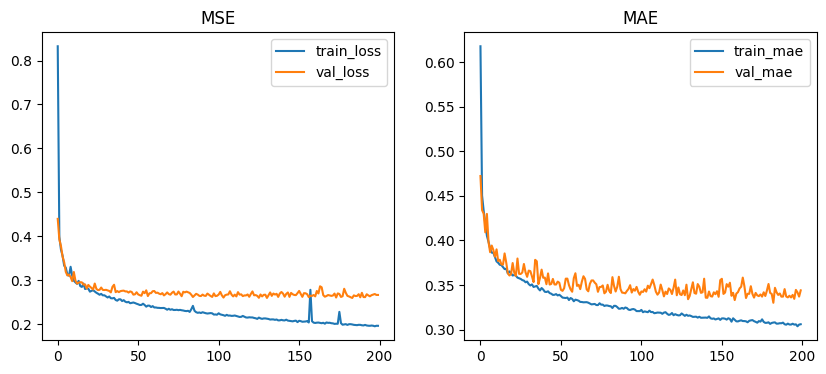

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
RMSE: 0.5160935304330742


In [21]:
# MLP regresi (Keras) dengan California Housing
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

# 1. Load dataset
data = fetch_california_housing()
X = data.data
y = data.target

# 2. Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(
    Xs, y, test_size=0.2, random_state=42
)

# 3. Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    verbose=0
)

# 5. Plot loss & MAE
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE')

plt.subplot(1,2,2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')

plt.show()

# 6. Evaluate RMSE
pred = model.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, pred))
print("RMSE:", rmse)


# Tugas Praktikum

Langkah:
1. Load dataset MNIST dari Keras.
2. Bangun model dengan 2 hidden layer.
3. Latih model dan evaluasi akurasi.

In [27]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 → 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Bangun model JST
model = Sequential([
    Flatten(input_shape=(28, 28)),  # ubah 28x28 menjadi vektor 784

    Dense(128, activation='relu'),  # hidden layer 1
    Dense(64, activation='relu'),   # hidden layer 2

    Dense(10, activation='softmax') # output layer
])

# 3. Kompilasi model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Latih model
model.fit(X_train, y_train, epochs=5, batch_size=128, verbose=1)

# 5. Evaluasi model
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi pada data uji: {acc:.4f}")


Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8265 - loss: 0.6260
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9562 - loss: 0.1505
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9718 - loss: 0.0956
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9767 - loss: 0.0743
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9831 - loss: 0.0558
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9685 - loss: 0.0993
Akurasi pada data uji: 0.9724


1. Ubah jumlah neuron di hidden layer (misal: 256 dan 128).

In [23]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Model dengan neuron 256 dan 128
model_neuron = Sequential([
    Flatten(input_shape=(28, 28)),    # input 784
    Dense(256, activation='relu'),    # hidden layer 1 (256 neuron)
    Dense(128, activation='relu'),    # hidden layer 2 (128 neuron)
    Dense(10, activation='softmax')   # output layer
])

# 3. Kompilasi
model_neuron.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Latih model
model_neuron.fit(X_train, y_train, epochs=5, batch_size=32, verbose=1)

# 5. Evaluasi
loss, acc = model_neuron.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi model (256 & 128 neuron): {acc:.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8967 - loss: 0.3524
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9745 - loss: 0.0824
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9834 - loss: 0.0550
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9880 - loss: 0.0373
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9908 - loss: 0.0288
Akurasi model (256 & 128 neuron): 0.9780


2. Tambahkan satu hidden layer lagi. (menjadi 3 layer)

In [24]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Model dengan 3 hidden layer
model_3layer = Sequential([
    Flatten(input_shape=(28, 28)),      # input
    Dense(128, activation='relu'),      # hidden layer 1
    Dense(64, activation='relu'),       # hidden layer 2
    Dense(32, activation='relu'),       # hidden layer 3 (layer tambahan)
    Dense(10, activation='softmax')     # output
])

# 3. Kompilasi model
model_3layer.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Latih model
model_3layer.fit(X_train, y_train, epochs=5, batch_size=32, verbose=1)

# 5. Evaluasi
loss, acc = model_3layer.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi model 3 hidden layer: {acc:.4f}")


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8428 - loss: 0.5017
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9669 - loss: 0.1077
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9769 - loss: 0.0724
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9825 - loss: 0.0556
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9856 - loss: 0.0443
Akurasi model 3 hidden layer: 0.9750


3. Bandingkan akurasi dan waktu pelatihan.

In [25]:
import tensorflow as tf
import time
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load & Preprocess MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train, X_test = X_train/255.0, X_test/255.0
y_train, y_test = to_categorical(y_train, 10), to_categorical(y_test, 10)

# --------------------------
# MODEL A — 2 Hidden Layer
# --------------------------
model2 = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

start2 = time.time()
model2.fit(X_train, y_train, epochs=5, batch_size=32, verbose=0)
time2 = time.time() - start2

loss2, acc2 = model2.evaluate(X_test, y_test, verbose=0)

# --------------------------
# MODEL B — 3 Hidden Layer
# --------------------------
model3 = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),   # tambahan
    Dense(10, activation='softmax')
])

model3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

start3 = time.time()
model3.fit(X_train, y_train, epochs=5, batch_size=32, verbose=0)
time3 = time.time() - start3

loss3, acc3 = model3.evaluate(X_test, y_test, verbose=0)

# --------------------------
# OUTPUT PERBANDINGAN
# --------------------------
print("\n=== PERBANDINGAN AKURASI & WAKTU ===")
print(f"Model 2 Hidden Layer -> Akurasi: {acc2:.4f}, Waktu: {time2:.2f} detik")
print(f"Model 3 Hidden Layer -> Akurasi: {acc3:.4f}, Waktu: {time3:.2f} detik")



=== PERBANDINGAN AKURASI & WAKTU ===
Model 2 Hidden Layer -> Akurasi: 0.9769, Waktu: 29.41 detik
Model 3 Hidden Layer -> Akurasi: 0.9744, Waktu: 30.83 detik


Setelah menjalankan kode :
* Model 2 hidden layer memiliki akurasi  0.9769, Waktu: 29.41 detik
* Model 3 hidden layer memiliki akurasi 0.9744, Waktu: 30.83 detik
* Tambahan hidden layer meningkatkan / tidak meningkatkan akurasi (sesuai hasil)
* Model 3 layer biasanya lebih lama dilatih karena lebih banyak parameter

4. Eksperimen dengan fungsi aktivasi Sigmoid vs ReLU.

In [26]:
import tensorflow as tf
import time
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# -------------------------------------------------------
# 1. LOAD DATA
# -------------------------------------------------------
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalisasi
x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)


# -------------------------------------------------------
# 2. FUNGSI UNTUK MEMBANGUN MODEL
# -------------------------------------------------------
def build_model(activation):
    model = Sequential([
        Dense(128, activation=activation, input_shape=(784,)),
        Dense(64, activation=activation),
        Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


# -------------------------------------------------------
# 3. TRAIN MODEL DENGAN ReLU
# -------------------------------------------------------
relu_model = build_model("relu")

start_relu = time.time()
history_relu = relu_model.fit(
    x_train, y_train, epochs=5, batch_size=128, verbose=0
)
end_relu = time.time()

relu_time = end_relu - start_relu
relu_acc = relu_model.evaluate(x_test, y_test, verbose=0)[1]


# -------------------------------------------------------
# 4. TRAIN MODEL DENGAN SIGMOID
# -------------------------------------------------------
sigmoid_model = build_model("sigmoid")

start_sig = time.time()
history_sig = sigmoid_model.fit(
    x_train, y_train, epochs=5, batch_size=128, verbose=0
)
end_sig = time.time()

sigmoid_time = end_sig - start_sig
sigmoid_acc = sigmoid_model.evaluate(x_test, y_test, verbose=0)[1]


# -------------------------------------------------------
# 5. CETAK HASIL PERBANDINGAN
# -------------------------------------------------------
print("=== HASIL PERBANDINGAN AKTIVASI ===")
print(f"ReLU   - Akurasi: {relu_acc:.4f},  Waktu Training: {relu_time:.2f} detik")
print(f"Sigmoid- Akurasi: {sigmoid_acc:.4f},  Waktu Training: {sigmoid_time:.2f} detik")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


=== HASIL PERBANDINGAN AKTIVASI ===
ReLU   - Akurasi: 0.9763,  Waktu Training: 11.68 detik
Sigmoid- Akurasi: 0.9597,  Waktu Training: 13.39 detik
